# BioSTEAM — Equipos de e-metanol: E202, EL101 y R401



In [ ]:

%pip -q install biosteam thermosteam graphviz pandas openpyxl matplotlib
!apt-get -qq update > /dev/null && apt-get -qq install -y graphviz > /dev/null


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)


## 1. Definición de las clases

E202: sobrecalentador eléctrico; EL101: SOEC; R401: reactor de síntesis

In [ ]:
"""Tres equipos personalizados para BioSTEAM: E202, EL101 y R401.

Modelo preliminar. No sustituye balances térmicos SOEC/ reactor rigurosos.
Las correlaciones de CAPEX y CEPCI proceden de los datos suministrados
por el usuario; requieren validación de fuente/base monetaria.
"""
import math
import biosteam as bst


class ElectricProcessHeater(bst.Unit):
    """Sobrecalentador eléctrico: 1 entrada, 1 salida."""
    _N_ins = 1
    _N_outs = 1
    _units = {'Duty': 'kJ/hr', 'Power': 'kW', 'Area': 'm2'}

    def __init__(self, ID='', ins=None, outs=(), thermo=None, *,
                 T_out=1073.15, P_out=2e6, max_heat_flux=28.0,
                 eta_th=0.985, cepci_factor=825.0/567.5):
        super().__init__(ID, ins, outs, thermo)
        self.T_out, self.P_out = T_out, P_out
        self.max_heat_flux, self.eta_th = max_heat_flux, eta_th
        self.cepci_factor = cepci_factor

    def _run(self):
        feed, = self.ins
        product, = self.outs
        if feed.F_mol <= 0 or self.T_out <= 0 or self.P_out <= 0:
            raise ValueError('E202: alimentación, T y P deben ser positivas.')
        if not 0 < self.eta_th <= 1 or self.max_heat_flux <= 0:
            raise ValueError('E202: eficiencia/flujo térmico no válidos.')
        if self.P_out > feed.P * (1 + 1e-9):
            raise ValueError('E202: un calentador no puede aumentar la presión sin compresor.')
        product.copy_like(feed)
        product.T, product.P = self.T_out, self.P_out
        product.phase = 'g'  # Modelo de sobrecalentamiento: salida vapor

    def _design(self):
        inlet, = self.ins
        outlet, = self.outs
        duty = outlet.H - inlet.H
        if duty < -1e-5:
            raise ValueError('E202: demanda de enfriamiento; no es un calentador.')
        duty = max(duty, 0.0)
        thermal_kW = duty/3600.0
        electric_kW = thermal_kW/self.eta_th
        self.design_results['Duty'] = duty
        self.design_results['Power'] = electric_kW
        self.design_results['Area'] = thermal_kW/self.max_heat_flux
        self.power_utility.consumption = electric_kW

    def _cost(self):
        kW = self.design_results['Power']
        name = 'Electric heater'
        base = (10**(3.24 + 0.72*math.log10(max(kW, 10.0))))*self.cepci_factor if kW > 0 else 0.0
        self.baseline_purchase_costs[name] = base
        self.F_BM[name] = 1.40 + 1.25*2.45*1.35


class SOECElectrolyzerSystem(bst.Unit):
    """SOEC de conversión especificada H2O -> H2 + 0.5 O2.

    SEC representa la electricidad AC; calor de reacción no se resuelve.
    """
    _N_ins = 1
    _N_outs = 2
    _units = {'Hydrogen production': 'kg/hr', 'Oxygen production': 'kg/hr',
              'AC power': 'kW', 'Actual SEC': 'kWh/kg', 'Water conversion': '%'}

    def __init__(self, ID='', ins=None, outs=(), thermo=None, *,
                 T_op=1073.15, P_op=2e6, conversion=0.70,
                 pressure_drop=0.03, SEC_kWh_kg=32.92,
                 P_AC_MW=38.0673, power_mode='SEC', n_cells=198000,
                 cost_per_cell=138.40, bare_module_factor=1.85):
        super().__init__(ID, ins, outs, thermo)
        self.T_op, self.P_op = T_op, P_op
        self.conversion, self.pressure_drop = conversion, pressure_drop
        self.SEC_kWh_kg, self.P_AC_MW, self.power_mode = SEC_kWh_kg, P_AC_MW, power_mode
        self.n_cells, self.cost_per_cell = n_cells, cost_per_cell
        self.bare_module_factor = bare_module_factor

    def _run(self):
        feed, = self.ins
        cathode, anode = self.outs
        if not 0 <= self.conversion <= 1 or not 0 <= self.pressure_drop < 1:
            raise ValueError('EL101: conversión o caída de presión inválida.')
        if self.P_op <= 0 or self.T_op <= 0 or self.P_op > feed.P*(1+1e-9):
            raise ValueError('EL101: temperatura/presión inválida o falta compresor.')
        if self.SEC_kWh_kg <= 0 or self.P_AC_MW < 0:
            raise ValueError('EL101: parámetros eléctricos inválidos.')
        water = feed.imol['Water']
        if water <= 0 or abs(feed.F_mol-water) > max(1e-8, 1e-8*feed.F_mol):
            raise ValueError('EL101: el modelo admite únicamente vapor de agua.')
        reacted = water*self.conversion
        cathode.empty(); anode.empty()
        cathode.imol['Hydrogen'] = reacted
        cathode.imol['Water'] = water-reacted
        anode.imol['Oxygen'] = reacted/2
        for stream in (cathode, anode):
            stream.T = self.T_op
            stream.P = self.P_op*(1-self.pressure_drop)
            stream.phase = 'g'
        h2_mass = cathode.imass['Hydrogen']
        if self.power_mode == 'SEC':
            power = h2_mass*self.SEC_kWh_kg
        elif self.power_mode == 'FIXED':
            power = self.P_AC_MW*1000
            if h2_mass <= 0 and power > 0:
                raise ValueError('EL101: potencia positiva sin producción de H2.')
        else:
            raise ValueError("EL101: power_mode='SEC' o 'FIXED'.")
        self.power_utility.consumption = power
        self._h2_mass, self._o2_mass = h2_mass, anode.imass['Oxygen']
        self._power = power

    def _design(self):
        self.design_results['Hydrogen production'] = self._h2_mass
        self.design_results['Oxygen production'] = self._o2_mass
        self.design_results['AC power'] = self._power
        self.design_results['Actual SEC'] = self._power/self._h2_mass if self._h2_mass else 0.0
        self.design_results['Water conversion'] = self.conversion*100

    def _cost(self):
        if self.n_cells <= 0 or self.cost_per_cell < 0 or self.bare_module_factor < 1:
            raise ValueError('EL101: parámetros de costo inválidos.')
        name = 'SOEC stacks / modular skid'
        self.baseline_purchase_costs[name] = self.n_cells*self.cost_per_cell
        self.F_BM[name] = self.bare_module_factor


class MultitubularBoilingWaterReactor(bst.Unit):
    """R401 síntesis CO2 + 3H2 -> CH3OH + H2O + vapor de coraza.

    La tasa de reacción y el duty se especifican independientemente;
    modelo preliminar sin cierre energético del reactor.
    """
    _N_ins = 2
    _N_outs = 2
    _units = {'Catalyst volume': 'm3', 'Transfer area': 'm2',
              'Methanol production': 'kmol/hr', 'Steam production': 'kg/hr',
              'Nominal cooling duty': 'kW'}

    def __init__(self, ID='', ins=None, outs=(), thermo=None, *,
                 T_rx=523.15, P_rx=7.5e6, V_cat=11.5,
                 rxn_mol_s=32.872, pressure_drop=0.04,
                 duty_kW=3385.0, P_steam=2e6, T_steam=485.55,
                 dh_vap_kJ_kg=1890.0, cepci_factor=825.0/567.5):
        super().__init__(ID, ins, outs, thermo)
        self.T_rx, self.P_rx, self.V_cat = T_rx, P_rx, V_cat
        self.rxn_mol_s, self.pressure_drop = rxn_mol_s, pressure_drop
        self.duty_kW = duty_kW
        self.P_steam, self.T_steam = P_steam, T_steam
        self.dh_vap_kJ_kg = dh_vap_kJ_kg
        self.cepci_factor = cepci_factor

    def _run(self):
        syngas, bfw = self.ins
        product, steam = self.outs
        if min(self.P_rx, self.P_steam, self.T_rx, self.T_steam) <= 0:
            raise ValueError('R401: T/P deben ser positivos.')
        if self.P_rx > syngas.P*(1+1e-9):
            raise ValueError('R401: falta compresión de syngas a P_rx.')
        if not 0 <= self.pressure_drop < 1 or self.rxn_mol_s < 0:
            raise ValueError('R401: caída de presión o reacción inválida.')
        if self.duty_kW < 0 or self.dh_vap_kJ_kg <= 0:
            raise ValueError('R401: duty o calor específico inválidos.')
        reacted = self.rxn_mol_s*3.6  # mol/s -> kmol/h
        if reacted > min(syngas.imol['CO2'],syngas.imol['Hydrogen']/3)+1e-8:
            raise ValueError('R401: falta CO2 o H2 para producción fijada.')
        required_bfw = self.duty_kW*3600/self.dh_vap_kJ_kg
        if abs(bfw.F_mass - bfw.imass['Water']) > 1e-6:
            raise ValueError('R401: BFW debe contener solamente agua.')
        if abs(bfw.imass['Water'] - required_bfw) > max(1e-5, required_bfw*1e-4):
            raise ValueError(f'R401: BFW necesario={required_bfw:.2f} kg/h, recibido={bfw.F_mass:.2f} kg/h.')
        product.copy_like(syngas)
        product.imol['CO2'] -= reacted
        product.imol['Hydrogen'] -= 3*reacted
        product.imol['Methanol'] += reacted
        product.imol['Water'] += reacted
        product.T, product.P = self.T_rx, self.P_rx*(1-self.pressure_drop)
        steam.copy_like(bfw)
        steam.T, steam.P, steam.phase = self.T_steam, self.P_steam, 'g'
        self._methanol_kmol_hr, self._steam_kg_hr = reacted, steam.F_mass

    def _design(self):
        self.design_results['Catalyst volume'] = self.V_cat
        self.design_results['Transfer area'] = 2126*math.pi*0.0381*6.0
        self.design_results['Methanol production'] = self._methanol_kmol_hr
        self.design_results['Steam production'] = self._steam_kg_hr
        self.design_results['Nominal cooling duty'] = self.duty_kW

    def _cost(self):
        A = self.design_results['Transfer area']
        base = 10**(4.15 + 0.58*math.log10(A))*self.cepci_factor
        name = 'Multitubular reactor'
        self.baseline_purchase_costs[name] = base
        self.F_BM[name] = 1.60 + 1.30*2.15*2.45


## 2. Configuración y condiciones nominales

La potencia del SOEC se calcula con el consumo específico de 32.92 kWh/kg H₂ (modo `SEC`).

In [ ]:
from pathlib import Path
import biosteam as bst
import pandas as pd
from IPython.display import display, Image

SALIDA = Path('/content/RESULTADOS_BIOSTEAM') if Path('/content').exists() else Path('RESULTADOS_BIOSTEAM')
SALIDA.mkdir(parents=True, exist_ok=True)

HORAS_ANUALES = 8000  # supuesto
PRECIO_ELECTRICIDAD = 0.10  # USD/kWh, supuesto
bst.PowerUtility.price = PRECIO_ELECTRICIDAD

chemicals = bst.Chemicals(['Water', 'Hydrogen', 'Oxygen', 'CO2', 'Methanol', 'CO'])
bst.settings.set_thermo(chemicals)

vapor = bst.Stream('steam_250C', Water=901.697142857, units='kmol/hr', T=523.15, P=2e6, phase='g')
E202 = ElectricProcessHeater('E202', ins=vapor, outs=('steam_800C',))
EL101 = SOECElectrolyzerSystem('EL101', ins=E202.outs[0], outs=('cathode_H2_H2O', 'anode_O2'), power_mode='SEC')
sistema_SOEC = bst.System('SOEC_TRAIN', path=(E202, EL101))

syngas = bst.Stream('syngas_75bar', CO2=140, Hydrogen=380, units='kmol/hr', T=500.0, P=7.5e6, phase='g')
bfw_kg_h = 3385 * 3600 / 1890
bfw = bst.Stream('BFW_R401', Water=bfw_kg_h, units='kg/hr', T=480.0, P=2e6, phase='l')
R401 = MultitubularBoilingWaterReactor('R401', ins=(syngas, bfw), outs=('reactor_out', 'steam_20bar'))
sistema_reactor = bst.System('REACTOR_TRAIN', path=(R401,))

sistema_SOEC.simulate()
sistema_reactor.simulate()
print('Simulación ejecutada. Resultados en:', SALIDA)


Simulación ejecutada. Resultados en: /content/RESULTADOS_BIOSTEAM


/usr/local/lib/python3.13/dist-packages/biosteam/_unit.py:1174: RuntimeWarning: `SOECElectrolyzerSystem._run` method added unit results (e.g., purchase costs, heat and power utilities); unit results should only be added in `_design` or `_cost` methods
  warn(


## 3. Diagramas del proceso


In [ ]:


!apt-get update -qq
!apt-get install -y graphviz
%pip install -q graphviz biosteam

import graphviz
import shutil
import subprocess

print("Graphviz ejecutable:", shutil.which("dot"))

resultado = subprocess.run(
    ["dot", "-V"],
    capture_output=True,
    text=True
)

print("Versión:", resultado.stderr or resultado.stdout)

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
graphviz is already the newest version (2.42.2-9ubuntu0.1).
0 upgraded, 0 newly installed, 0 to remove and 29 not upgraded.
Graphviz ejecutable: /usr/bin/dot
Versión: dot - graphviz version 2.43.0 (0)



Archivo generado: /content/RESULTADOS_BIOSTEAM/DIAGRAMA_EQUIPOS.png


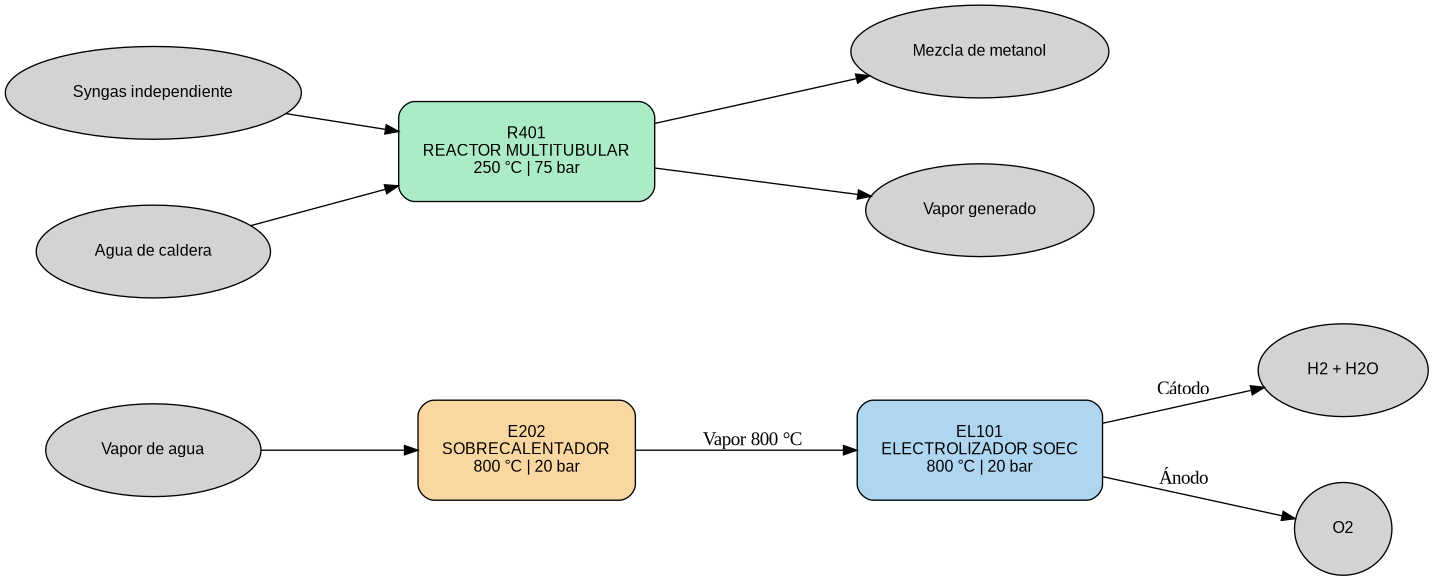

In [ ]:
# DIAGRAMA REAL DE UNIDADES BIOSTEAM
# E202 -> EL101
# R401 REPRESENTADO COMO SISTEMA INDEPENDIENTE

from graphviz import Digraph
from IPython.display import display, Image
from pathlib import Path

SALIDA = Path("/content/RESULTADOS_BIOSTEAM")
SALIDA.mkdir(parents=True, exist_ok=True)

dot = Digraph(
    "BIOSTEAM_EQUIPOS",
    format="png"
)

dot.attr(
    rankdir="LR",
    bgcolor="white",
    splines="polyline",
    nodesep="0.7",
    ranksep="1.0"
)

dot.attr(
    "node",
    shape="box",
    style="rounded,filled",
    fontname="Arial",
    fontsize="12",
    margin="0.25"
)

# EQUIPOS

dot.node(
    "E202",
    "E202\nSOBRECALENTADOR\n800 °C | 20 bar",
    fillcolor="#FAD7A0"
)

dot.node(
    "EL101",
    "EL101\nELECTROLIZADOR SOEC\n800 °C | 20 bar",
    fillcolor="#AED6F1"
)

dot.node(
    "R401",
    "R401\nREACTOR MULTITUBULAR\n250 °C | 75 bar",
    fillcolor="#ABEBC6"
)

# CORRIENTES

dot.node("VAPOR", "Vapor de agua", shape="ellipse")
dot.node("H2", "H2 + H2O", shape="ellipse")
dot.node("O2", "O2", shape="ellipse")
dot.node("SYNGAS", "Syngas independiente", shape="ellipse")
dot.node("BFW", "Agua de caldera", shape="ellipse")
dot.node("MEOH", "Mezcla de metanol", shape="ellipse")
dot.node("STEAM", "Vapor generado", shape="ellipse")

# CONEXIONES REALES

dot.edge("VAPOR", "E202")
dot.edge("E202", "EL101", label="Vapor 800 °C")
dot.edge("EL101", "H2", label="Cátodo")
dot.edge("EL101", "O2", label="Ánodo")

dot.edge("SYNGAS", "R401")
dot.edge("BFW", "R401")
dot.edge("R401", "MEOH")
dot.edge("R401", "STEAM")

# GENERAR Y MOSTRAR

archivo = dot.render(
    filename=str(SALIDA / "DIAGRAMA_EQUIPOS"),
    cleanup=True
)

print("Archivo generado:", archivo)

display(Image(filename=archivo))

In [ ]:
for sist in (sistema_SOEC, sistema_reactor):
    destino = SALIDA / f'{sist.ID}.png'
    try:
        sist.diagram(kind='thorough', format='png', file=str(destino))
        if destino.exists():
            display(Image(filename=str(destino)))
        else:
            print('Diagrama solicitado:', destino)
    except Exception as error:
        print(f'No se pudo generar el diagrama {sist.ID}: {error}')


Diagrama solicitado: /content/RESULTADOS_BIOSTEAM/SOEC_TRAIN.png
Diagrama solicitado: /content/RESULTADOS_BIOSTEAM/REACTOR_TRAIN.png


/usr/local/lib/python3.13/dist-packages/biosteam/digraph/digraph.py:604: RuntimeWarning: a 'ValueError' was raised when generating graphviz diagram, possibly due to graphviz installation issues, make sure Graphviz executables are on your systems' PATH
  warn(


## 4. CAPEX y OPEX eléctrico por equipo

CAPEX de compra/instalado se obtiene de los métodos de costo de cada clase. OPEX presentado = **electricidad únicamente**; no incluye mantenimiento, catalizador, reposición de stacks, BFW, CO₂, personal ni recuperación térmica. No sumar OPEX eléctrico con `utility_cost` sin revisar posible duplicación.

In [ ]:
filas = []
for equipo in (E202, EL101, R401):
    potencia_neta = equipo.power_utility.consumption - equipo.power_utility.production
    filas.append({
        'Equipo': equipo.ID,
        'Tipo': type(equipo).__name__,
        'CAPEX compra (USD)': equipo.purchase_cost,
        'CAPEX instalado (USD)': equipo.installed_cost,
        'Electricidad neta (kW)': potencia_neta,
        'OPEX electricidad (USD/año)': potencia_neta * HORAS_ANUALES * PRECIO_ELECTRICIDAD,
    })
df = pd.DataFrame(filas)
display(df.style.format({c: '{:,.2f}' for c in df.columns if c not in ('Equipo', 'Tipo')}))

resumen = pd.DataFrame([
    {'Indicador':'CAPEX compra equipos (USD)', 'Valor': df['CAPEX compra (USD)'].sum()},
    {'Indicador':'CAPEX instalado equipos (USD)', 'Valor': df['CAPEX instalado (USD)'].sum()},
    {'Indicador':'OPEX electricidad (USD/año)', 'Valor': df['OPEX electricidad (USD/año)'].sum()},
])
display(resumen)
ruta_excel = SALIDA / 'CAPEX_OPEX_equipos.xlsx'
with pd.ExcelWriter(ruta_excel) as writer:
    df.to_excel(writer, sheet_name='Equipos', index=False)
    resumen.to_excel(writer, sheet_name='Resumen', index=False)
print('Excel guardado:', ruta_excel)


,Equipo,Tipo,CAPEX compra (USD),CAPEX instalado (USD),Electricidad neta (kW),OPEX electricidad (USD/año)
0,E202,ElectricProcessHeater,"1,232,825.21","6,822,917.01","5,418.86","4,335,084.02"
1,EL101,SOECElectrolyzerSystem,"27,403,200.00","50,695,920.00","41,887.38","33,509,907.05"
2,R401,MultitubularBoilingWaterReactor,"1,442,400.65","12,185,040.13",0.00,0.00


,Indicador,Valor
0,CAPEX compra equipos (USD),3.01e+07
1,CAPEX instalado equipos (USD),6.97e+07
2,OPEX electricidad (USD/año),3.78e+07


Excel guardado: /content/RESULTADOS_BIOSTEAM/CAPEX_OPEX_equipos.xlsx


## 5. Gráficas económicas

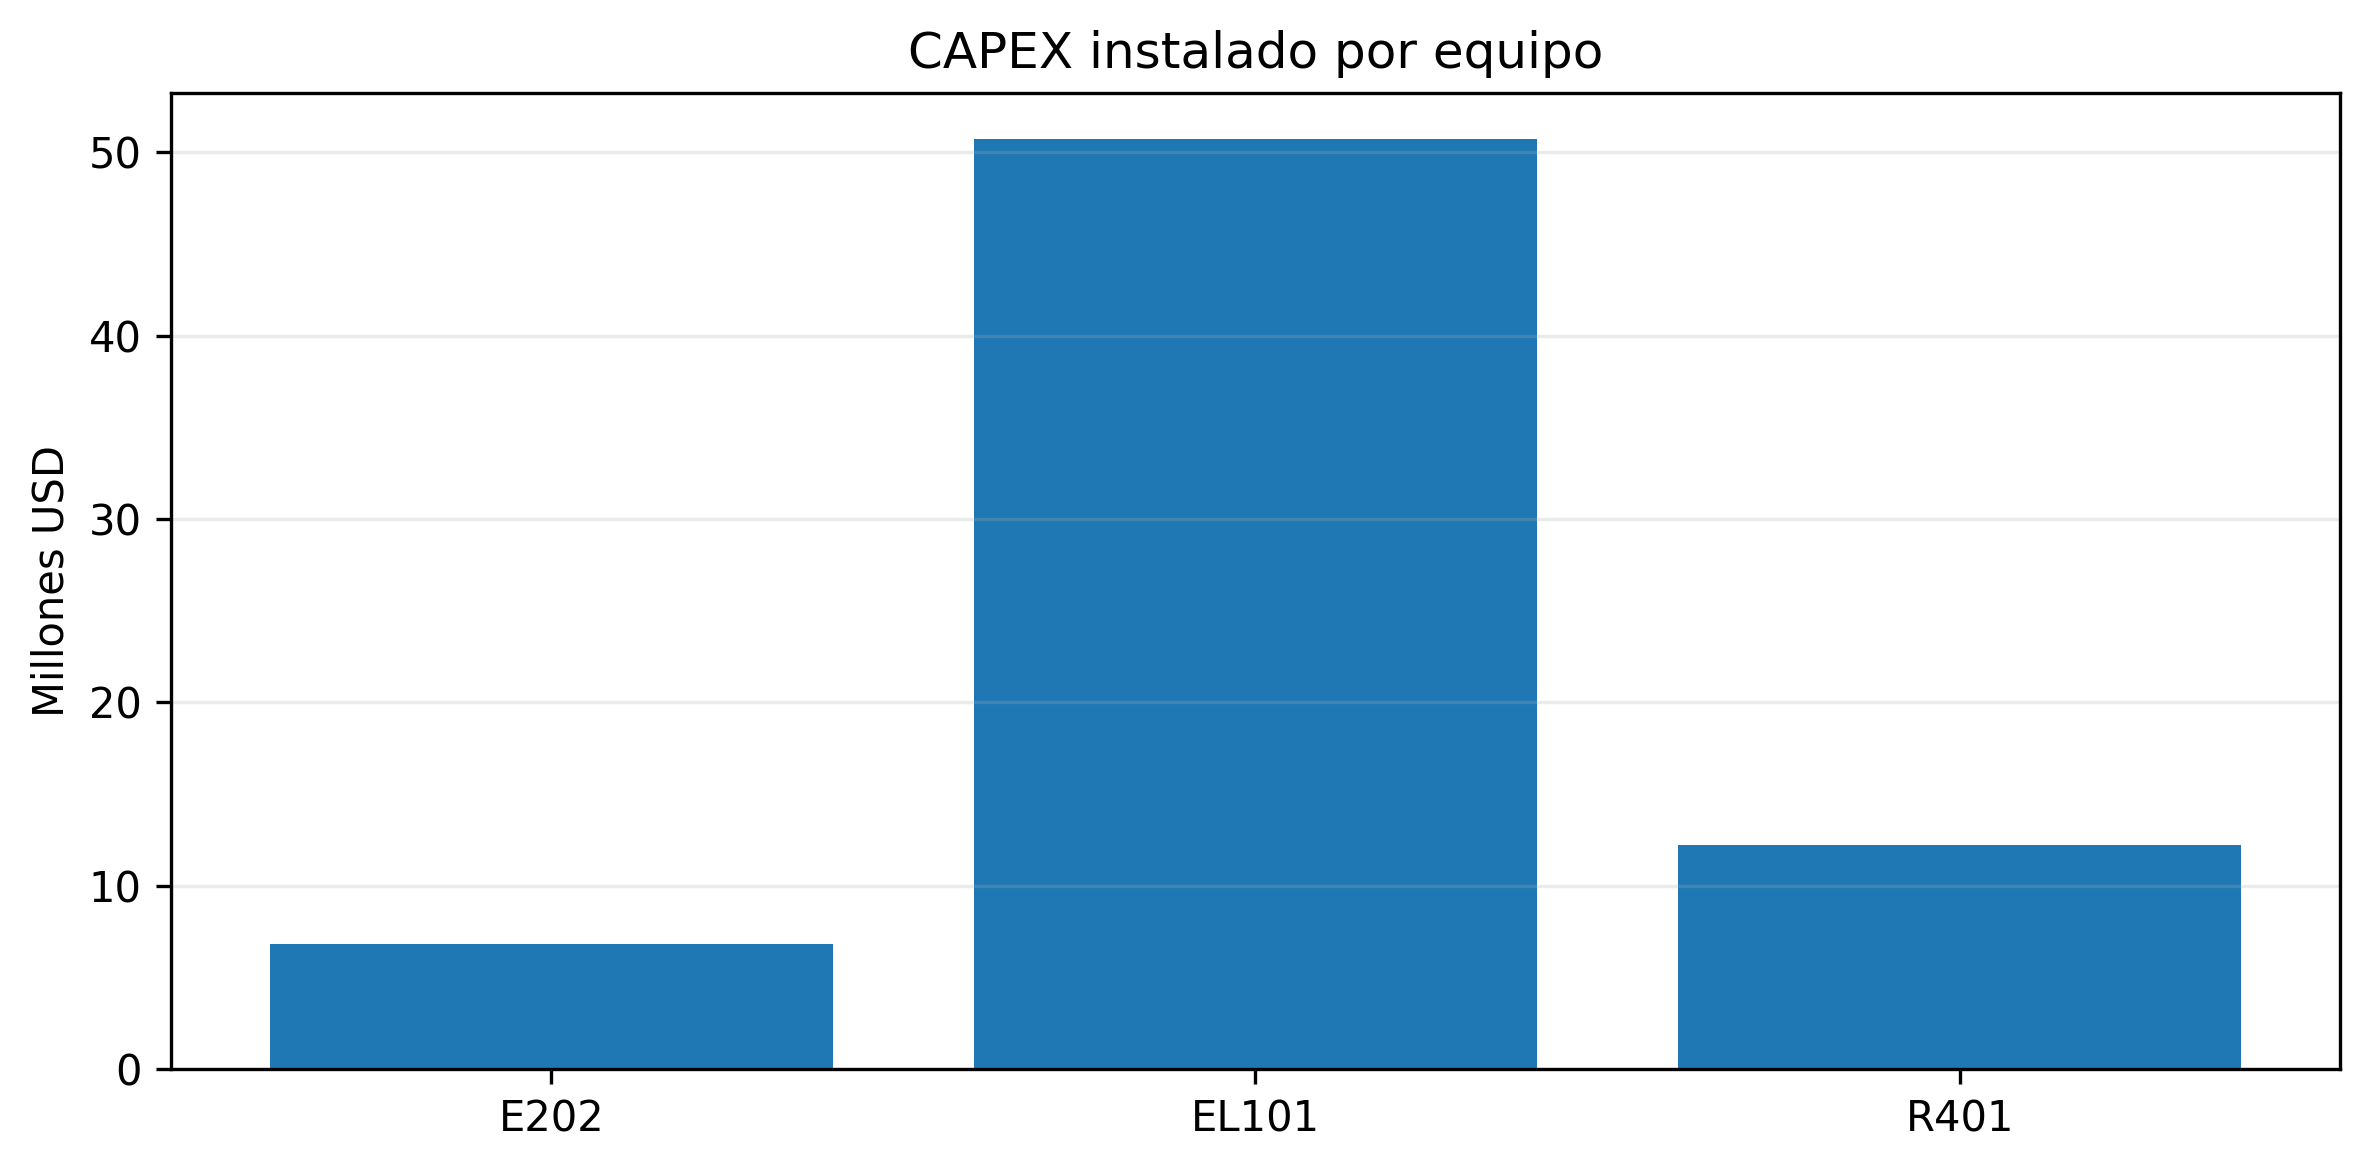

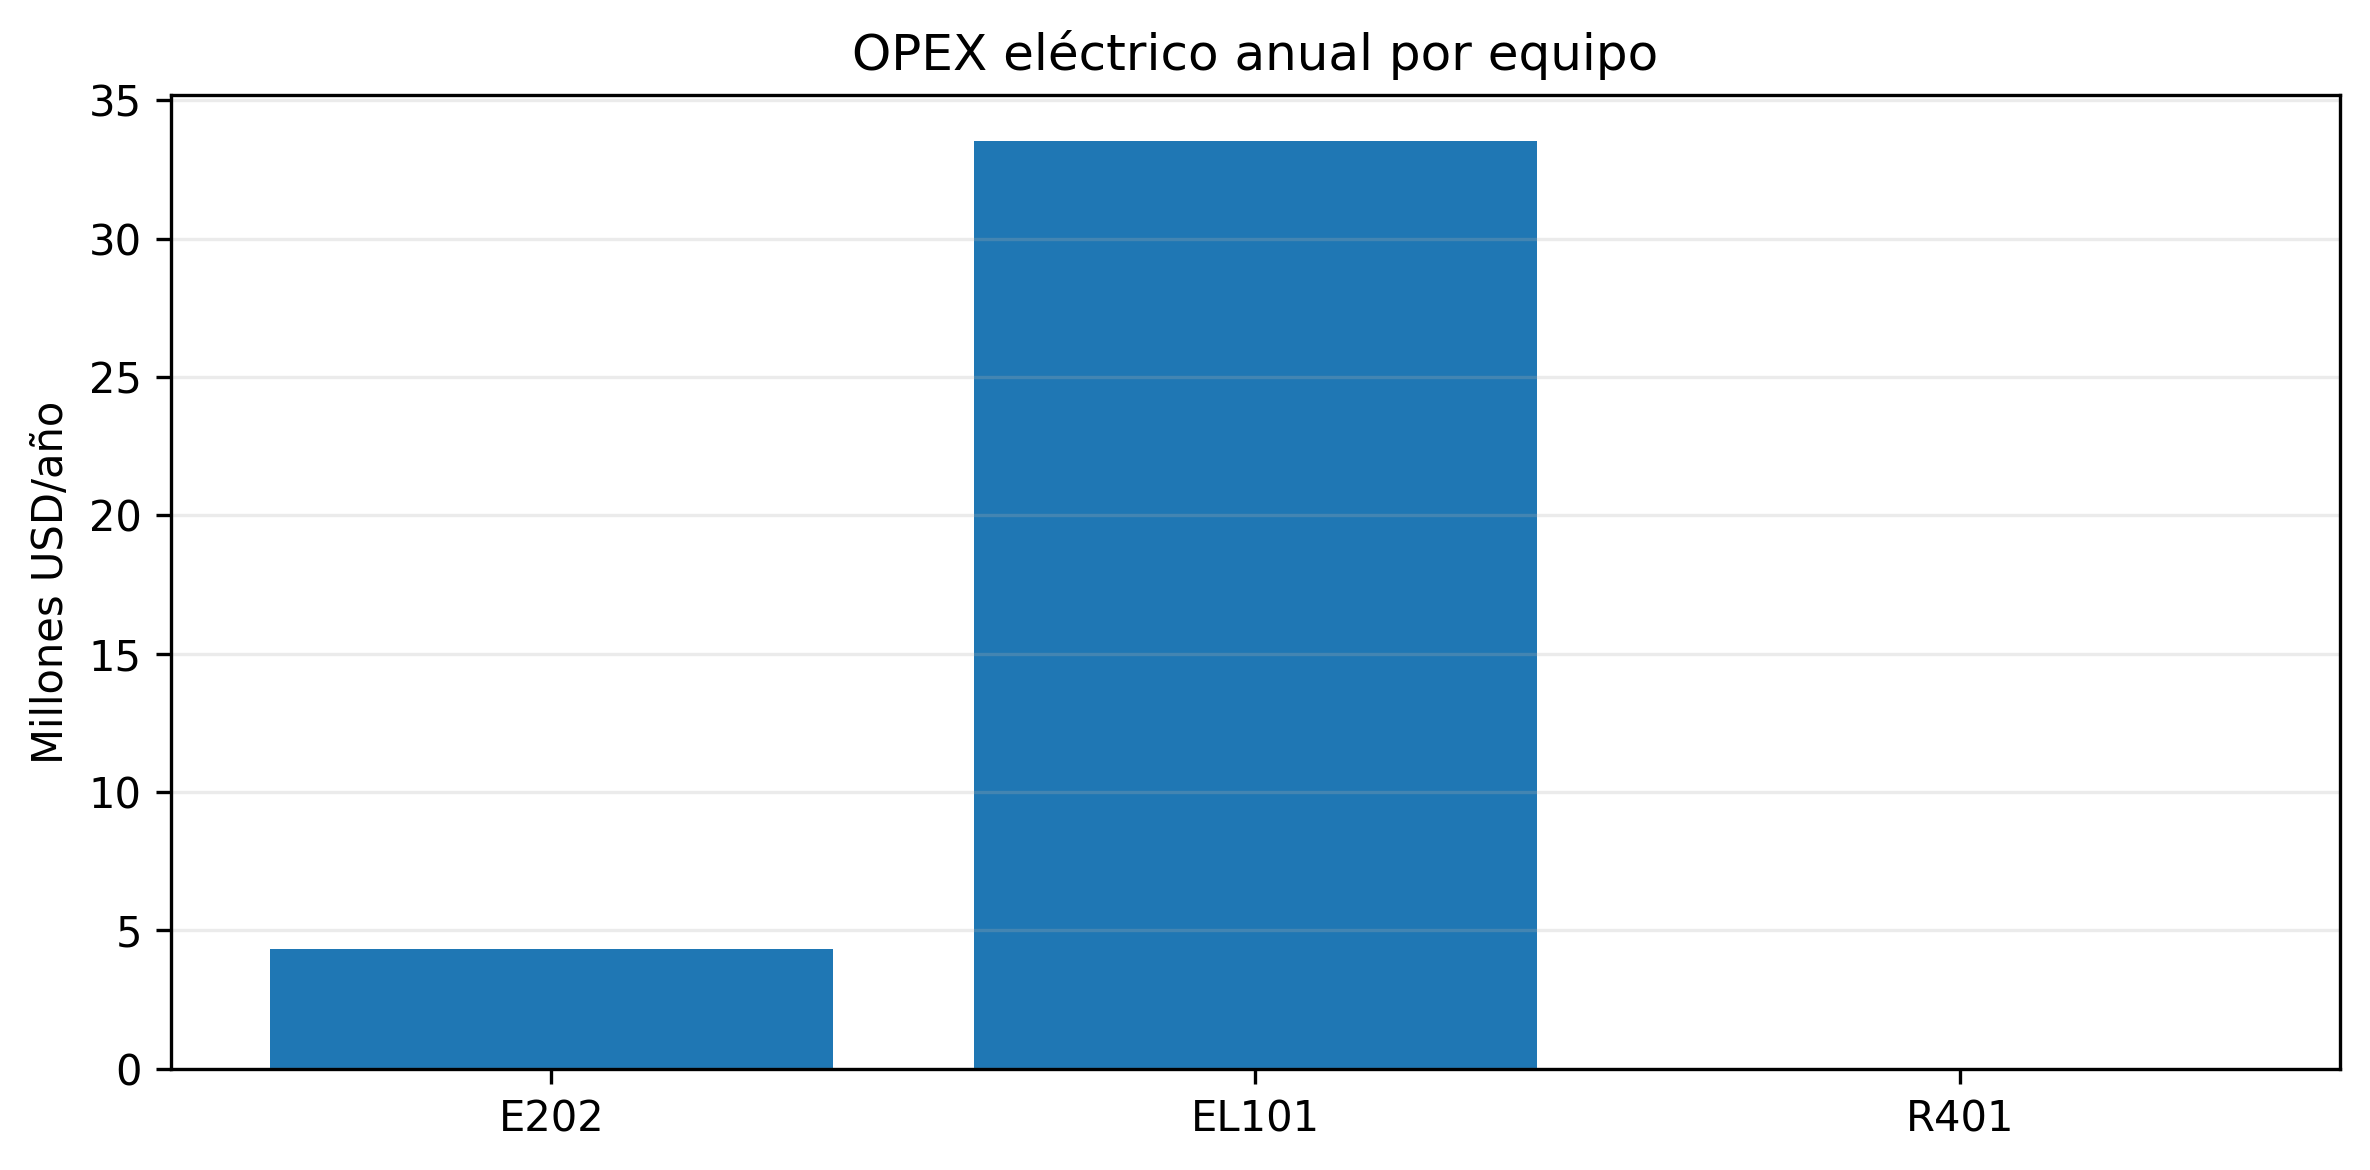

In [ ]:
import matplotlib.pyplot as plt

for columna, titulo, nombre in [
    ('CAPEX instalado (USD)', 'CAPEX instalado por equipo', 'CAPEX_por_equipo.png'),
    ('OPEX electricidad (USD/año)', 'OPEX eléctrico anual por equipo', 'OPEX_por_equipo.png'),
]:
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.bar(df['Equipo'], df[columna]/1e6)
    ax.set_title(titulo)
    ax.set_ylabel('Millones USD' + ('/año' if 'OPEX' in columna else ''))
    ax.grid(axis='y', alpha=.25)
    fig.tight_layout()
    fig.savefig(SALIDA / nombre, dpi=200)
    plt.show()


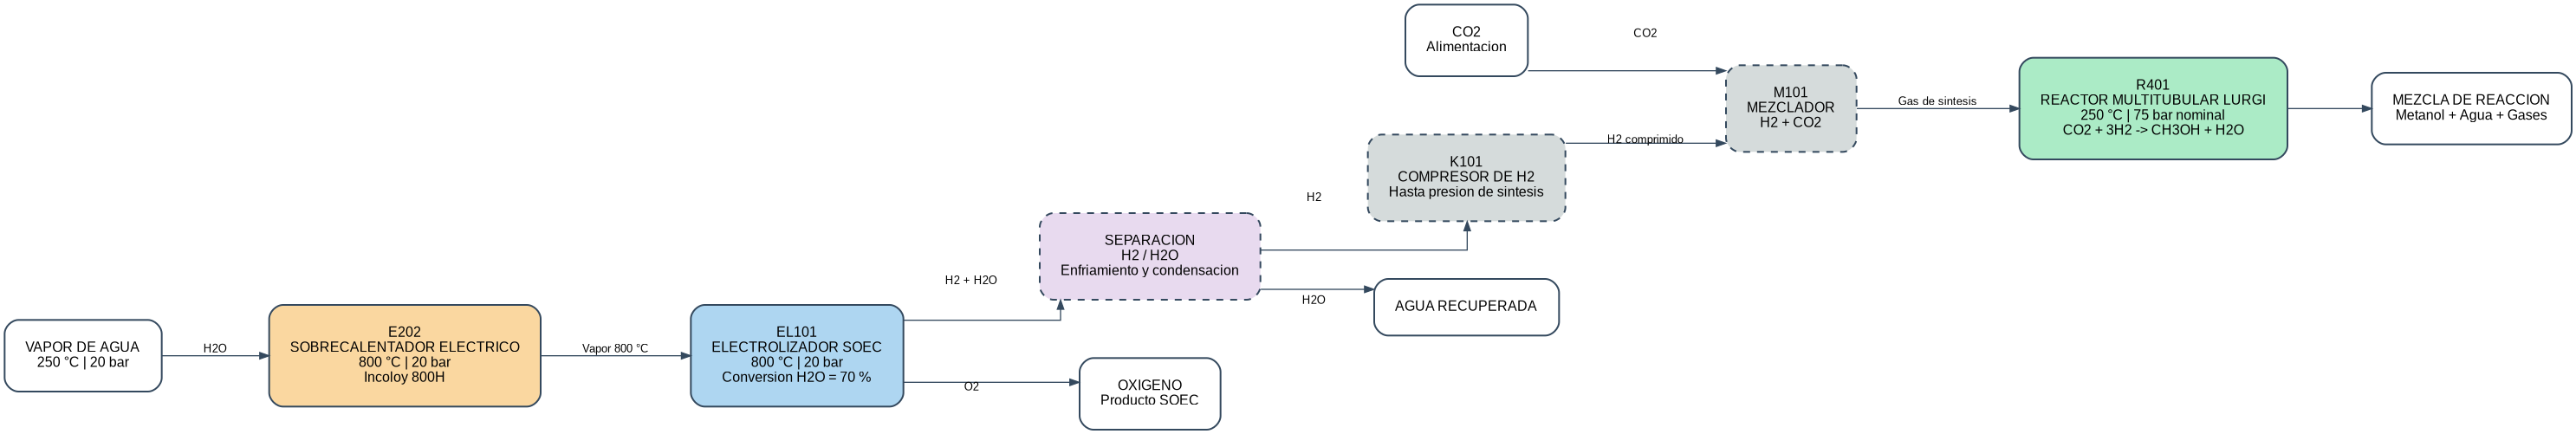

Diagrama generado: /content/Diagrama_Secuencial_E_Metanol.png


In [ ]:
# DIAGRAMA SECUENCIAL DE LOS EQUIPOS DE E-METANOL
# E202 -> EL101 -> SEPARACION -> COMPRESION -> R401

!pip -q install graphviz
!apt-get -qq install graphviz > /dev/null

from graphviz import Digraph
from IPython.display import display, Image

# Crear diagrama
dot = Digraph(
    name="PLANTA_E_METANOL",
    format="png"
)

# Configuración general
dot.attr(
    rankdir="LR",
    splines="ortho",
    nodesep="0.7",
    ranksep="1.0",
    bgcolor="white"
)

dot.attr(
    "node",
    shape="box",
    style="rounded,filled",
    fontname="Arial",
    fontsize="12",
    color="#34495E",
    penwidth="1.5",
    margin="0.25"
)

dot.attr(
    "edge",
    fontname="Arial",
    fontsize="10",
    color="#34495E",
    arrowsize="0.8"
)

# EQUIPOS ORIGINALES

dot.node(
    "E202",
    "E202\n"
    "SOBRECALENTADOR ELECTRICO\n"
    "800 °C | 20 bar\n"
    "Incoloy 800H",
    fillcolor="#FAD7A0"
)

dot.node(
    "EL101",
    "EL101\n"
    "ELECTROLIZADOR SOEC\n"
    "800 °C | 20 bar\n"
    "Conversion H2O = 70 %",
    fillcolor="#AED6F1"
)

dot.node(
    "R401",
    "R401\n"
    "REACTOR MULTITUBULAR LURGI\n"
    "250 °C | 75 bar nominal\n"
    "CO2 + 3H2 -> CH3OH + H2O",
    fillcolor="#ABEBC6"
)

# EQUIPOS INTERMEDIOS NECESARIOS
# Representación conceptual, no simulados aquí

dot.node(
    "SEP",
    "SEPARACION\n"
    "H2 / H2O\n"
    "Enfriamiento y condensacion",
    fillcolor="#E8DAEF",
    style="rounded,filled,dashed"
)

dot.node(
    "K101",
    "K101\n"
    "COMPRESOR DE H2\n"
    "Hasta presion de sintesis",
    fillcolor="#D5DBDB",
    style="rounded,filled,dashed"
)

dot.node(
    "M101",
    "M101\n"
    "MEZCLADOR\n"
    "H2 + CO2",
    fillcolor="#D5DBDB",
    style="rounded,filled,dashed"
)

# CORRIENTES DE ALIMENTACION

dot.node(
    "VAPOR",
    "VAPOR DE AGUA\n250 °C | 20 bar",
    fillcolor="#FFFFFF"
)

dot.node(
    "CO2",
    "CO2\nAlimentacion",
    fillcolor="#FFFFFF"
)

# CONEXIONES SECUENCIALES

dot.edge("VAPOR", "E202", label="H2O")

dot.edge(
    "E202",
    "EL101",
    label="Vapor 800 °C"
)

dot.edge(
    "EL101",
    "SEP",
    label="H2 + H2O"
)

dot.edge(
    "SEP",
    "K101",
    label="H2"
)

dot.edge(
    "K101",
    "M101",
    label="H2 comprimido"
)

dot.edge(
    "CO2",
    "M101",
    label="CO2"
)

dot.edge(
    "M101",
    "R401",
    label="Gas de sintesis"
)

# PRODUCTOS SECUNDARIOS

dot.node(
    "O2",
    "OXIGENO\nProducto SOEC",
    fillcolor="#FFFFFF"
)

dot.node(
    "AGUA",
    "AGUA RECUPERADA",
    fillcolor="#FFFFFF"
)

dot.node(
    "METANOL",
    "MEZCLA DE REACCION\nMetanol + Agua + Gases",
    fillcolor="#FFFFFF"
)

dot.edge("EL101", "O2", label="O2")
dot.edge("SEP", "AGUA", label="H2O")
dot.edge("R401", "METANOL")

# GENERAR IMAGEN

archivo = dot.render(
    filename="/content/Diagrama_Secuencial_E_Metanol",
    cleanup=True
)

display(Image(filename=archivo))

print("Diagrama generado:", archivo)